In [1]:
import pandas as pd
from pathlib import Path

BASE = Path(r"C:\Users\Administrator\credit-scoring-lc")
df = pd.read_parquet(BASE / "data" / "processed" / "loans_clean.parquet")

print(df.shape)
df.head()

(546018, 26)


,id,issue_date,issue_year,split,default_flag,loan_amnt,purpose,initial_list_status,emp_length_yrs,home_ownership,...,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,total_acc,pub_rec,pub_rec_bankruptcies,revol_bal,revol_util,credit_hist_months
0,68407277,2015-12-01,2015,test,0,3600.0,debt_consolidation,w,10.0,MORTGAGE,...,1.0,30.0,NaN,7.0,13.0,0.0,0.0,2765.0,29.7,148
1,68355089,2015-12-01,2015,test,0,24700.0,small_business,w,10.0,MORTGAGE,...,4.0,6.0,NaN,22.0,38.0,0.0,0.0,21470.0,19.2,192
2,68426831,2015-12-01,2015,test,0,11950.0,debt_consolidation,w,4.0,RENT,...,0.0,NaN,NaN,5.0,6.0,0.0,0.0,8822.0,68.4,338
3,68476668,2015-12-01,2015,test,0,20000.0,debt_consolidation,f,10.0,MORTGAGE,...,0.0,49.0,NaN,12.0,27.0,0.0,0.0,87329.0,84.5,306
4,67275481,2015-12-01,2015,test,0,20000.0,major_purchase,w,10.0,MORTGAGE,...,0.0,3.0,NaN,8.0,15.0,0.0,0.0,826.0,5.7,202


In [2]:
df.dtypes

id                            str
issue_date                 object
issue_year                  int64
split                         str
default_flag                int32
loan_amnt                 float64
purpose                       str
initial_list_status           str
emp_length_yrs            float64
home_ownership                str
annual_inc                float64
verification_status           str
addr_state                    str
dti                       float64
fico                      float64
delinq_2yrs               float64
inq_last_6mths            float64
mths_since_last_delinq    float64
mths_since_last_record    float64
open_acc                  float64
total_acc                 float64
pub_rec                   float64
pub_rec_bankruptcies      float64
revol_bal                 float64
revol_util                float64
credit_hist_months          int64
dtype: object

In [3]:
num_cols = ["loan_amnt", "emp_length_yrs", "annual_inc", "dti", "fico",
            "delinq_2yrs", "inq_last_6mths", "mths_since_last_delinq",
            "mths_since_last_record", "open_acc", "total_acc", "pub_rec",
            "pub_rec_bankruptcies", "revol_bal", "revol_util", "credit_hist_months"]
cat_cols = ["purpose", "initial_list_status", "home_ownership",
            "verification_status", "addr_state"]

df[num_cols].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
loan_amnt,546018.0,12714.7,7870.7,1000.0,7000.0,10000.0,16850.0,35000.0
emp_length_yrs,512417.0,5.9,3.7,0.0,2.0,6.0,10.0,10.0
annual_inc,546018.0,73280.2,66833.2,0.0,43450.0,61000.0,88500.0,9000000.0
dti,546016.0,17.9,8.4,0.0,11.6,17.3,23.8,999.0
fico,546018.0,695.5,30.3,662.0,672.0,687.0,712.0,847.5
delinq_2yrs,546018.0,0.3,0.9,0.0,0.0,0.0,0.0,30.0
inq_last_6mths,546018.0,0.7,1.0,0.0,0.0,0.0,1.0,6.0
mths_since_last_delinq,273941.0,34.0,21.8,0.0,15.0,31.0,50.0,188.0
mths_since_last_record,96259.0,69.8,27.3,0.0,51.0,69.0,91.0,121.0
open_acc,546018.0,11.4,5.3,0.0,8.0,10.0,14.0,84.0


In [4]:
checks = {
    "dti > 100":           (df["dti"] > 100).sum(),
    "dti 空值":             df["dti"].isna().sum(),
    "annual_inc == 0":     (df["annual_inc"] == 0).sum(),
    "annual_inc > 500000": (df["annual_inc"] > 500000).sum(),
    "revol_util > 100":    (df["revol_util"] > 100).sum(),
    "revol_util 空值":      df["revol_util"].isna().sum(),
    "revol_bal > 200000":  (df["revol_bal"] > 200000).sum(),
}
pd.Series(checks)

dti > 100                 5
dti 空值                    2
annual_inc == 0           2
annual_inc > 500000     660
revol_util > 100       2192
revol_util 空值           259
revol_bal > 200000     1145
dtype: int64

In [5]:
train = df[df["split"] == "train"]
cols = ["annual_inc", "dti", "revol_bal", "revol_util"]
train[cols].quantile([0.01, 0.05, 0.50, 0.95, 0.99, 0.999]).T.round(1)

,0.010,0.050,0.500,0.950,0.990,0.999
annual_inc,18000.0,26000.0,60000.0,150000.0,250000.0,500000.0
dti,2.1,5.0,16.8,31.0,34.8,39.3
revol_bal,508.9,2188.0,10810.0,39365.0,80964.1,243569.2
revol_util,3.8,15.9,56.1,91.8,97.8,102.2


In [6]:
train = df[df["split"] == "train"].copy()
train["fico_bin"] = pd.cut(train["fico"], bins=[660, 680, 700, 720, 740, 760, 850])

train.groupby("fico_bin", observed=True)["default_flag"].agg(
    n_loans="count", default_rate="mean"
).round(4)

,n_loans,default_rate
fico_bin,,
"(660, 680]",95265,0.1699
"(680, 700]",74510,0.1399
"(700, 720]",47709,0.1060
"(720, 740]",23100,0.0794
"(740, 760]",10802,0.0624
"(760, 850]",11606,0.0443


In [7]:
train = df[df["split"] == "train"].copy()
train["fico_bin"] = pd.cut(train["fico"], bins=[660, 680, 700, 720, 740, 760, 850])

train.groupby("fico_bin", observed=True)["default_flag"].agg(
    n_loans="count", default_rate="mean"
).round(4)

,n_loans,default_rate
fico_bin,,
"(660, 680]",95265,0.1699
"(680, 700]",74510,0.1399
"(700, 720]",47709,0.1060
"(720, 740]",23100,0.0794
"(740, 760]",10802,0.0624
"(760, 850]",11606,0.0443


In [8]:
def rate_by_bin(col, q=10):
    t = train[[col, "default_flag"]].copy()
    t["bin"] = pd.qcut(t[col], q=q, duplicates="drop")
    return t.groupby("bin", observed=True)["default_flag"].agg(
        n_loans="count", default_rate="mean"
    ).round(4)

rate_by_bin("dti")

,n_loans,default_rate
bin,,
"(-0.001, 7.1]",26337,0.0992
"(7.1, 10.08]",26294,0.1043
"(10.08, 12.45]",26352,0.1080
"(12.45, 14.62]",26277,0.1140
"(14.62, 16.8]",26315,0.1234
"(16.8, 19.06]",26268,0.1293
"(19.06, 21.53]",26260,0.1413
"(21.53, 24.46]",26340,0.1514
"(24.46, 28.21]",26268,0.1665


In [9]:
def rate_by_cat(col):
    return train.groupby(col)["default_flag"].agg(
        n_loans="count", default_rate="mean"
    ).round(4).sort_values("default_rate", ascending=False)

rate_by_cat("purpose")

,n_loans,default_rate
purpose,,
small_business,2647,0.2289
moving,1699,0.1942
medical,2653,0.1685
other,12937,0.1590
house,1004,0.1554
vacation,1587,0.1525
wedding,509,0.1395
debt_consolidation,152387,0.1368
renewable_energy,143,0.1329


In [10]:
rate_by_bin("revol_util")

,n_loans,default_rate
bin,,
"(-0.001, 24.1]",26433,0.1003
"(24.1, 34.5]",26328,0.1161
"(34.5, 42.5]",26124,0.1202
"(42.5, 49.5]",26300,0.1318
"(49.5, 56.1]",26437,0.1339
"(56.1, 62.6]",26097,0.1340
"(62.6, 69.4]",26345,0.1427
"(69.4, 77.0]",26577,0.1418
"(77.0, 86.1]",26156,0.1423


In [11]:
import pandas as pd
from pathlib import Path

BASE = Path(r"C:\Users\Administrator\credit-scoring-lc")
df = pd.read_parquet(BASE / "data" / "processed" / "loans_clean.parquet")
train = df[df["split"] == "train"].copy()

num_cols = ["loan_amnt", "emp_length_yrs", "annual_inc", "dti", "fico",
            "delinq_2yrs", "inq_last_6mths", "mths_since_last_delinq",
            "mths_since_last_record", "open_acc", "total_acc", "pub_rec",
            "pub_rec_bankruptcies", "revol_bal", "revol_util", "credit_hist_months"]
cat_cols = ["purpose", "initial_list_status", "home_ownership",
            "verification_status", "addr_state"]

print(df.shape, train.shape)   #重启准备工作，读取数据等。因为lab重启了，系统无法读取。

(546018, 26) (262992, 26)


In [12]:
rows = []
for c in num_cols:
    if c in ["fico", "dti", "revol_util"]:
        continue
    t = train[[c, "default_flag"]].dropna().copy()
    t["bin"] = pd.qcut(t[c], q=5, duplicates="drop")
    r = t.groupby("bin", observed=True)["default_flag"].mean()
    rows.append({"variable": c, "n_bins": len(r),
                 "low_bin": r.iloc[0], "high_bin": r.iloc[-1],
                 "ratio": r.iloc[-1] / r.iloc[0]})

pd.DataFrame(rows).round(3).sort_values("ratio")

,variable,n_bins,low_bin,high_bin,ratio
2,annual_inc,5,0.185,0.090,0.485
12,credit_hist_months,5,0.159,0.113,0.710
11,revol_bal,5,0.146,0.105,0.722
8,total_acc,5,0.150,0.121,0.804
0,loan_amnt,5,0.135,0.114,0.840
1,emp_length_yrs,4,0.137,0.119,0.872
5,mths_since_last_delinq,5,0.143,0.136,0.953
3,delinq_2yrs,1,0.132,0.132,1.000
10,pub_rec_bankruptcies,1,0.132,0.132,1.000
9,pub_rec,1,0.132,0.132,1.000


In [13]:
for c in ["delinq_2yrs", "pub_rec", "pub_rec_bankruptcies"]:
    g = train[c].clip(upper=2)
    print(c, "（2 表示 2 及以上）")
    print(train.groupby(g)["default_flag"].agg(
        n_loans="count", default_rate="mean").round(4), "\n")

delinq_2yrs （2 表示 2 及以上）
             n_loans  default_rate
delinq_2yrs                       
0.0           212695        0.1303
1.0            33336        0.1337
2.0            16961        0.1485 

pub_rec （2 表示 2 及以上）
         n_loans  default_rate
pub_rec                       
0.0       219563        0.1294
1.0        37238        0.1433
2.0         6191        0.1513 

pub_rec_bankruptcies （2 表示 2 及以上）
                      n_loans  default_rate
pub_rec_bankruptcies                       
0.0                    229408        0.1301
1.0                     32062        0.1429
2.0                      1522        0.1715 



In [14]:
def rate_by_cat(col):
    return train.groupby(col)["default_flag"].agg(
        n_loans="count", default_rate="mean"
    ).round(4).sort_values("default_rate", ascending=False)

for c in ["home_ownership", "verification_status", "initial_list_status"]:
    print(c)
    print(rate_by_cat(c), "\n")

home_ownership
                n_loans  default_rate
home_ownership                       
RENT             111311        0.1574
OWN               25188        0.1390
MORTGAGE         126492        0.1081
ANY                   1        0.0000 

verification_status
                     n_loans  default_rate
verification_status                       
Verified               83323        0.1433
Source Verified        81467        0.1380
Not Verified           98202        0.1172 

initial_list_status
                     n_loans  default_rate
initial_list_status                       
f                     157902        0.1346
w                     105090        0.1279 



In [15]:
s = rate_by_cat("addr_state")
s = s[s["n_loans"] >= 1000]

print("违约率最高的 8 个州")
print(s.head(8), "\n")
print("违约率最低的 8 个州")
print(s.tail(8))

违约率最高的 8 个州
            n_loans  default_rate
addr_state                       
NV             3917        0.1654
TN             4013        0.1615
AL             3084        0.1595
OK             2310        0.1584
AR             1991        0.1512
FL            18022        0.1476
MO             4099        0.1461
NY            22594        0.1449 

违约率最低的 8 个州
            n_loans  default_rate
addr_state                       
IL            10634        0.1136
CT             3905        0.1117
WA             6023        0.1104
CO             5581        0.1077
SC             3031        0.1056
KS             2360        0.1008
WV             1264        0.0926
NH             1243        0.0901


In [16]:
for c in ["mths_since_last_delinq", "mths_since_last_record", "emp_length_yrs"]:
    g = train[c].isna().map({True: "空值", False: "有值"})
    print(c)
    print(train.groupby(g)["default_flag"].agg(
        n_loans="count", default_rate="mean").round(4), "\n")

mths_since_last_delinq
                        n_loans  default_rate
mths_since_last_delinq                       
有值                       126753        0.1345
空值                       136239        0.1295 

mths_since_last_record
                        n_loans  default_rate
mths_since_last_record                       
有值                        43429        0.1445
空值                       219563        0.1294 

emp_length_yrs
                n_loans  default_rate
emp_length_yrs                       
有值               248351        0.1283
空值                14641        0.1940 



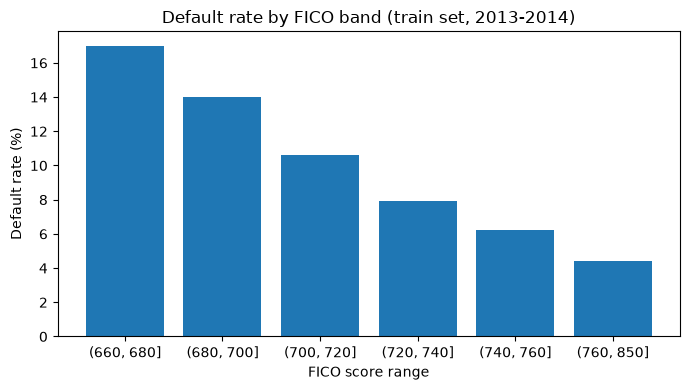

In [17]:
import matplotlib.pyplot as plt

t = train.copy()
t["fico_bin"] = pd.cut(t["fico"], bins=[660, 680, 700, 720, 740, 760, 850])
r = t.groupby("fico_bin", observed=True)["default_flag"].mean() * 100

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(r.index.astype(str), r.values)
ax.set_xlabel("FICO score range")
ax.set_ylabel("Default rate (%)")
ax.set_title("Default rate by FICO band (train set, 2013-2014)")
plt.tight_layout()

(BASE / "reports" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(BASE / "reports" / "figures" / "default_rate_by_fico.png", dpi=150)
plt.show()